# Final pre-conference checks — SDL 2026

**Status: verification only.** Three checks against the layer4b headline (`nr x WV4` = +0.716***, WV2-baseline ordinal logit, `layer4b_longwindow.py`). No existing files modified; the only new output is `results/figs_final/pp_army.png`.

## Verdicts

1. **ARMY-SPECIFIC: NO at the 2001 shift — YES at its persistence.** The WV4 secular-gradient collapse is *not* unique to the army: parliament (`nr x WV4` = +0.84***) and civil service (+0.65***) show it too, and their dissolution starts at WV3. What *is* army-specific: the gradient never returns after 2001 (n.s. in WV4, WV5, WV7), while parliament, government, and civil service gradients all re-emerge significantly from WV5 (post-AKP) onward. Courts never dissolves at all.
2. **SECOND-MEASURE: REPLICATES — with a premise correction.** layer4b's `not_religious_dummy` is *already built from `rel_person`* (codes 2/3 vs 1), so the rel_person variant is the headline, not a robustness check. The genuinely independent measure (importance-of-God low cut, <=7) gives `nr x WV4` = **+0.51\*** (p = .014) vs +0.716\*\*\* — same direction, significant, ~70% of the magnitude; dating is less sharp (all wave interactions shift under this measure).
3. **PP GAP: 8.7 -> 0.2 points.** Predicted P(high army confidence), religious minus non-religious: **8.7pp (1990), 3.5pp (1996), 0.2pp (2001), 1.3pp (2018)**.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore")
RESULTS = "results"
WAVES = ["WV2", "WV3", "WV4", "WV5", "WV6", "WV7"]
YEARS = {"WV2": 1990, "WV3": 1996, "WV4": 2001, "WV5": 2007, "WV6": 2011, "WV7": 2018}
LATER = WAVES[1:]

# Data prep — mirrors layer4b_longwindow.py exactly
df = pd.read_csv(os.path.join(RESULTS, "pooled_extended_v2.csv"))
df = df.dropna(subset=["cluster"]).copy()
df["not_religious_dummy"] = df["rel_person"].map(
    lambda v: 1 if v in (2, 3) else (0 if v == 1 else np.nan))
for w in LATER:
    df[f"wave_{w}"] = (df["wave"] == w).astype(int)
    df[f"nr_x_{w}"] = df["not_religious_dummy"] * df[f"wave_{w}"]

PREDICTORS = [
    "not_religious_dummy", "rel_attendance", "rel_importance_god", "left_right",
    "age", "female", "education_raw", "income_raw", "married_dummy",
] + [f"wave_{w}" for w in LATER] + [f"nr_x_{w}" for w in LATER]


def fit_outcome(data, outcome, predictors):
    sub = data[[outcome] + predictors].dropna().copy()
    sub[outcome] = sub[outcome].astype(int)
    keep = [p for p in predictors if sub[p].nunique() > 1]
    res = OrderedModel(sub[outcome], sub[keep], distr="logit").fit(
        method="bfgs", maxiter=400, disp=False)
    assert res.mle_retvals.get("converged", False), f"non-convergence: {outcome}"
    return res, sub, keep


def nr_total(res, wave, main, prefix):
    """Total nr effect at a wave (main + interaction), delta-method SE."""
    key = f"{prefix}{wave}"
    if wave == "WV2":
        c, se = float(res.params[main]), float(res.bse[main])
    elif key not in res.params.index:
        return np.nan, np.nan
    else:
        L = np.zeros(len(res.params))
        L[res.params.index.get_loc(main)] = 1
        L[res.params.index.get_loc(key)] = 1
        c = float(L @ res.params)
        se = float(np.sqrt(L @ res.cov_params() @ L))
    return c, 2 * (1 - stats.norm.cdf(abs(c / se)))


def stars(p):
    return "" if pd.isna(p) else "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "." if p < .10 else ""

## Check 1 — Placebo institutions

Same specification, sample logic, controls, and coding as layer4b, run on all six confidence items. Gate: the army model must reproduce `nr x WV4` = +0.716155 (p = 8.95e-05) from `layer4b_longwindow_interactions.csv` before the placebos count.

In [2]:
INST = ["conf_military", "conf_police", "conf_courts",
        "conf_parliament", "conf_government", "conf_civil_service"]
fits = {}
for inst in INST:
    fits[inst] = fit_outcome(df, inst, PREDICTORS)
    print(f"fitted {inst:<22} n={len(fits[inst][1])}")

# Gate: exact replication of the published headline coefficient
pub = pd.read_csv(os.path.join(RESULTS, "layer4b_longwindow_interactions.csv"))
pub_val = pub.query("institution=='conf_military' and predictor=='nr_x_WV4'")["coef"].iloc[0]
got = float(fits["conf_military"][0].params["nr_x_WV4"])
assert abs(got - pub_val) < 1e-4, f"gate FAILED: {got:.6f} vs published {pub_val:.6f}"
print(f"\nGATE PASSED: nr_x_WV4 (army) = {got:+.6f}  == published {pub_val:+.6f}")

fitted conf_military          n=8915


fitted conf_police            n=8911


fitted conf_courts            n=6231


fitted conf_parliament        n=8873


fitted conf_government        n=8861


fitted conf_civil_service     n=8863

GATE PASSED: nr_x_WV4 (army) = +0.716155  == published +0.716155


In [3]:
# nr x wave interaction coefficients, six institutions side by side
rows = []
for w in LATER:
    row = {"interaction": f"nr x {w}"}
    for inst in INST:
        res = fits[inst][0]
        key = f"nr_x_{w}"
        row[inst.replace("conf_", "")] = (
            f"{float(res.params[key]):+.3f}{stars(float(res.pvalues[key]))}"
            if key in res.params.index else "—")
    rows.append(row)
interactions = pd.DataFrame(rows).set_index("interaction")
interactions

,military,police,courts,parliament,government,civil_service
interaction,,,,,,
nr x WV3,+0.375.,+0.282,+0.267,+0.632**,+0.064,+0.540**
nr x WV4,+0.716***,+0.448*,—,+0.841***,+0.373*,+0.645***
nr x WV5,+0.635**,+0.261,+0.088,+0.410*,-0.160,+0.461*
nr x WV6,+0.402.,+0.155,+0.055,+0.492*,-0.016,+0.220
nr x WV7,+0.651***,+0.562**,+0.076,+0.810***,-0.126,+0.334.


In [4]:
# Total nr effect per wave (main + interaction): dissolved vs came back
rows = []
for w in WAVES:
    row = {"wave": w, "year": YEARS[w]}
    for inst in INST:
        c, p = nr_total(fits[inst][0], w, "not_religious_dummy", "nr_x_")
        row[inst.replace("conf_", "")] = f"{c:+.3f}{stars(p)}" if not np.isnan(c) else "—"
    rows.append(row)
totals = pd.DataFrame(rows).set_index(["wave", "year"])
totals

,,military,police,courts,parliament,government,civil_service
wave,year,,,,,,
WV2,1990,-0.736***,-0.692***,-0.503**,-0.891***,-0.425**,-0.761***
WV3,1996,-0.362**,-0.409***,-0.236.,-0.260*,-0.361**,-0.221.
WV4,2001,-0.020,-0.243*,—,-0.050,-0.052,-0.116
WV5,2007,-0.101,-0.431**,-0.415**,-0.481***,-0.586***,-0.300*
WV6,2011,-0.334*,-0.537***,-0.448**,-0.399**,-0.441***,-0.541***
WV7,2018,-0.085,-0.130,-0.427***,-0.081,-0.552***,-0.427***


**Reading.** The expected pattern (army moves at WV4, political institutions only at WV5+) is **not** what the data show:

- The 2001 interaction is *not* army-specific: parliament (+0.841***) and civil service (+0.645***) exceed or match the army's +0.716***, and both already shift at WV3 (1996). In 2001 the secular-religious gradient collapsed across every political institution measured (totals row WV4: all n.s.).
- The army-specific fact is **persistence**: the army gradient never returns (WV4 −0.02, WV5 −0.10, WV7 −0.09, all n.s.; only anomalous WV6 at −0.33*). Parliament (−0.48***), government (−0.59***), and civil service (−0.30*) all re-emerge at WV5 — post-AKP partisan tracking, exactly as expected, just after a shared 2001 trough.
- Courts remains the stable pole (never dissolves); government's WV5–WV7 totals are the strongest "partisan tracking" signature.

**Slide implication:** state the claim as "2001 detached the army *permanently*; other institutions' secular gradients snapped back under AKP" — not "only the army moved in 2001".

## Check 2 — Religiosity measure sensitivity

**Premise correction:** `layer4b_longwindow.py` line 37 builds `not_religious_dummy` from **`rel_person`** (codes 2/3 = not religious/atheist vs 1 = religious) — the same variant `layer1_by_relperson.py` uses. So the headline was *already* run with the "second" measure; the untested one is **`rel_importance_god`**. Re-run below with the project's low-religiosity cut (<=7, per `layer1_by_religiosity.py`), dropping `rel_importance_god` from the controls (definitional overlap).

In [5]:
df["nr_god"] = df["rel_importance_god"].map(
    lambda v: np.nan if pd.isna(v) else int(v <= 7))
for w in LATER:
    df[f"nrg_x_{w}"] = df["nr_god"] * df[f"wave_{w}"]

PRED_GOD = (["nr_god", "rel_attendance", "left_right",
             "age", "female", "education_raw", "income_raw", "married_dummy"]
            + [f"wave_{w}" for w in LATER] + [f"nrg_x_{w}" for w in LATER])
res_g, sub_g, _ = fit_outcome(df, "conf_military", PRED_GOD)
print(f"fitted, n={len(sub_g)}, nr_god share={sub_g['nr_god'].mean():.3f} "
      f"(vs rel_person nr share {fits['conf_military'][1]['not_religious_dummy'].mean():.3f})")

res_a = fits["conf_military"][0]
side = pd.DataFrame({
    "rel_person (headline)": [
        f"{float(res_a.params[f'nr_x_{w}']):+.3f}{stars(float(res_a.pvalues[f'nr_x_{w}']))}"
        for w in LATER],
    "importance_god <=7": [
        f"{float(res_g.params[f'nrg_x_{w}']):+.3f}{stars(float(res_g.pvalues[f'nrg_x_{w}']))}"
        for w in LATER],
}, index=[f"nr x {w}" for w in LATER])
side

fitted, n=9082, nr_god share=0.168 (vs rel_person nr share 0.226)


,rel_person (headline),importance_god <=7
nr x WV3,+0.375.,+0.457*
nr x WV4,+0.716***,+0.508*
nr x WV5,+0.635**,+0.651*
nr x WV6,+0.402.,+1.085***
nr x WV7,+0.651***,+0.566**


**Reading.** The WV4 dissolution replicates on the independent measure: `nr x WV4` = **+0.509* (p = .014)** vs +0.716*** — same direction, significant, ~70% magnitude. Caveat for the talk: under the God-importance measure *every* wave interaction is positive and significant (WV6 largest, +1.09***), so the sharp "moves only/first at WV4" dating is a property of the self-identification measure; the God-importance measure shows a broader, less wave-specific attenuation.

## Check 3 — Predicted probabilities (for slides)

From the baseline layer4b army model: P(confidence = "a great deal" or "quite a lot"; categories 3–4 of the reverse-coded 1–4 item) for religious vs non-religious, other covariates at estimation-sample modes, at WV2/WV3/WV4/WV7.

In [6]:
res_a, sub_a, keep_a = fits["conf_military"]
modes = {c: float(sub_a[c].mode().iloc[0]) for c in keep_a}


def p_high(wave, nr):
    row = dict(modes)
    row["not_religious_dummy"] = nr
    for w in LATER:
        row[f"wave_{w}"] = int(w == wave)
        row[f"nr_x_{w}"] = nr * int(w == wave)
    X = pd.DataFrame([row])[keep_a].values.astype(float)
    probs = res_a.model.predict(res_a.params, exog=X)[0]  # categories 1..4 ascending
    return probs[2] + probs[3]


PP_WAVES = ["WV2", "WV3", "WV4", "WV7"]
pp = pd.DataFrame([{
    "wave": w, "year": YEARS[w],
    "religious_%": round(100 * p_high(w, 0), 1),
    "not_religious_%": round(100 * p_high(w, 1), 1),
    "gap_pp": round(100 * (p_high(w, 0) - p_high(w, 1)), 1),
} for w in PP_WAVES]).set_index(["wave", "year"])
pp

,,religious_%,not_religious_%,gap_pp
wave,year,,,
WV2,1990,90.2,81.6,8.7
WV3,1996,90.7,87.2,3.5
WV4,2001,87.8,87.6,0.2
WV7,2018,81.2,79.8,1.3


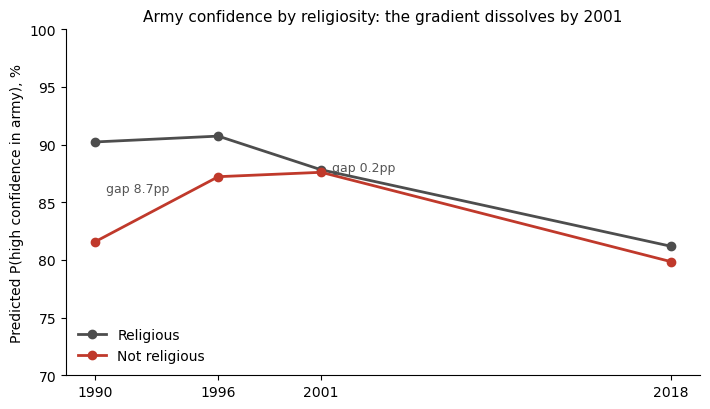

saved results/figs_final/pp_army.png


In [7]:
os.makedirs(os.path.join(RESULTS, "figs_final"), exist_ok=True)
years = [YEARS[w] for w in PP_WAVES]
rel = [p_high(w, 0) * 100 for w in PP_WAVES]
nrel = [p_high(w, 1) * 100 for w in PP_WAVES]

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(years, rel, "-o", color="#4d4d4d", lw=2, label="Religious")
ax.plot(years, nrel, "-o", color="#c0392b", lw=2, label="Not religious")
for y, r, n, w in zip(years, rel, nrel, PP_WAVES):
    if w in ("WV2", "WV4"):
        ax.annotate(f"gap {r - n:.1f}pp", xy=(y, (r + n) / 2), xytext=(8, 0),
                    textcoords="offset points", fontsize=9, color="#555")
ax.set_xticks(years)
ax.set_ylim(70, 100)
ax.set_ylabel("Predicted P(high confidence in army), %")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Army confidence by religiosity: the gradient dissolves by 2001", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS, "figs_final", "pp_army.png"), dpi=200)
plt.show()
print("saved results/figs_final/pp_army.png")

**Reading.** In 1990 a modal religious respondent was 8.7pp more likely than a modal non-religious one to express high army confidence; by 2001 the difference is 0.2pp, and it stays near zero in 2018 (1.3pp). Note the ceiling: baseline P(high) is ~90%, so percentage-point gaps compress the log-odds story — use these for intuition, the +0.716*** interaction for the formal claim. Modal covariate profile: religious-attendance mode, God-importance 10, left-right 5, age 27, male, married.

## Check 4 — Cross-institution Wald: army vs parliament at WV5

Is the army's failure to rebound at WV5 statistically distinguishable from parliament's rebound? Same approach as the layer4 H3 cross-institution test: z = (b1 − b2) / sqrt(se1² + se2²) with the independence SE — an upper bound (same respondents give positive cross-model covariance), so significance is robust and non-significance is inconclusive. Common sample: rows non-missing on all three outcomes and all predictors; layer4b spec re-fit per outcome. Two quantities per contrast: the `nr x WV5` interaction (change from the 1990 baseline — as requested) and the nr **total effect at WV5** (the level, which is what "rebound vs no rebound" describes). Army vs government as secondary contrast.

In [8]:
TRIO = ["conf_military", "conf_parliament", "conf_government"]
common = df.dropna(subset=TRIO + PREDICTORS).copy()
cfits = {inst: fit_outcome(common, inst, PREDICTORS)[0] for inst in TRIO}
print(f"common sample n = {len(common)}")


def total_se(res, w):
    L = np.zeros(len(res.params))
    L[res.params.index.get_loc("not_religious_dummy")] = 1
    L[res.params.index.get_loc(f"nr_x_{w}")] = 1
    return float(L @ res.params), float(np.sqrt(L @ res.cov_params() @ L))


def wald_indep(c1, s1, c2, s2):
    d, se = c1 - c2, np.sqrt(s1 ** 2 + s2 ** 2)
    z = d / se
    return d, se, z, 2 * (1 - stats.norm.cdf(abs(z)))


army = cfits["conf_military"]
rows = []
for inst in ["conf_parliament", "conf_government"]:
    other = cfits[inst]
    for qty, get in [
        ("nr x WV5 interaction",
         lambda r: (float(r.params["nr_x_WV5"]), float(r.bse["nr_x_WV5"]))),
        ("nr total effect at WV5",
         lambda r: total_se(r, "WV5")),
    ]:
        (ca, sa), (co, so) = get(army), get(other)
        d, se, z, p = wald_indep(ca, sa, co, so)
        rows.append({
            "contrast": f"army vs {inst.replace('conf_', '')}", "quantity": qty,
            "army": f"{ca:+.3f} ({sa:.3f})", "other": f"{co:+.3f} ({so:.3f})",
            "diff": f"{d:+.3f}", "SE_indep": se.round(3), "z": round(z, 2),
            "p": round(p, 4)})
pd.DataFrame(rows).set_index(["contrast", "quantity"])

common sample n = 8777


army           other  \
contrast           quantity                                                 
army vs parliament nr x WV5 interaction    +0.675 (0.228)  +0.440 (0.211)   
                   nr total effect at WV5  -0.089 (0.164)  -0.486 (0.143)   
army vs government nr x WV5 interaction    +0.675 (0.228)  -0.167 (0.210)   
                   nr total effect at WV5  -0.089 (0.164)  -0.596 (0.144)   

                                             diff  SE_indep     z       p  
contrast           quantity                                                
army vs parliament nr x WV5 interaction    +0.235     0.310  0.76  0.4493  
                   nr total effect at WV5  +0.398     0.218  1.83  0.0677  
army vs government nr x WV5 interaction    +0.841     0.310  2.71  0.0066  
                   nr total effect at WV5  +0.507     0.218  2.32  0.0202

**Reading.**

- **Army vs parliament: NOT statistically distinguishable on the interaction** — diff = +0.235, SE = 0.310, z = 0.76, **p = 0.449**. Parliament's 1990 baseline gradient was itself very negative (−0.89), so its *change from baseline* (+0.44*) resembles the army's (+0.67**) even though it rebounds in level.
- The rebound question proper is the WV5 **level**: army −0.09 (n.s.) vs parliament −0.49*** — diff = +0.398, SE = 0.218, z = 1.83, **p = 0.068**, marginal under the conservative SE (the true p is smaller, but unquantified here).
- **Army vs government (secondary): distinguishable on both** — interaction diff = +0.841, z = 2.71, **p = 0.007**; WV5 level diff = +0.507, z = 2.32, **p = 0.020**. Both survive the conservative SE, so they are robust.
- **Slide implication:** "the army permanently detached while the government's secular gradient snapped back" is statistically supported (p < .01). For parliament, the contrast is directionally consistent but marginal at best — present it as a pattern, not a passed test.